# Workbook for correcting MM4250 raw data with ECal

Use definitions in the tier2_scikit_rf_caldata directory to correct raw recorded data at RF channels of the MM4250. The example data already in 'raw_data' is from a flat short standard at each of the RF channel outputs. 

To use this workbook, add user raw data files to the 'raw_data' directory with the following file names:
- ecal_load.s1p
- ecal_open.s1p
- ecal_short.s1p
- rf1.s1p
- rf2.s1p
- rf3.s1p
- rf4.s1p
- rf5.s1p
- rf6.s1p

In [1]:
# Select whether to use 3K or 295K calibration standards
USE_3K_STANDARDS = False

In [3]:
# load needed python libraries matplotlib, numpy, and scikit-rf
import matplotlib.pyplot as plt
import numpy as np
import skrf as rf

In [13]:
# read in raw data
rawdata = rf.read_all('raw_data_september_menlo')

# define sets of mesaured data from ecal
my_measured_ecal = [\
        rawdata['ecal_short'],
        rawdata['ecal_open'],
        rawdata['ecal_load'],
        ]

# read in data from tier 2 scikit-rf calibration data files
if USE_3K_STANDARDS:
        tier2_cal_files_scikitrf = rf.read_all('tier2_scikitrf_caldata/tier2_3k2')
else:
        tier2_cal_files_scikitrf = rf.read_all('tier2_scikitrf_caldata/tier2_295k2')

# define sets of ideals from tier 2 at each port from the first 6x6cal data set
my_ideals_scikitrf_port1 = [\
        tier2_cal_files_scikitrf['port1_short_tier2'],
        tier2_cal_files_scikitrf['port1_open_tier2'],
        tier2_cal_files_scikitrf['port1_load_tier2'],
        ]
my_ideals_scikitrf_port2 = [\
        tier2_cal_files_scikitrf['port2_short_tier2'],
        tier2_cal_files_scikitrf['port2_open_tier2'],
        tier2_cal_files_scikitrf['port2_load_tier2'],
        ]
my_ideals_scikitrf_port3 = [\
        tier2_cal_files_scikitrf['port3_short_tier2'],
        tier2_cal_files_scikitrf['port3_open_tier2'],
        tier2_cal_files_scikitrf['port3_load_tier2'],
        ]
my_ideals_scikitrf_port4 = [\
        tier2_cal_files_scikitrf['port4_short_tier2'],
        tier2_cal_files_scikitrf['port4_open_tier2'],
        tier2_cal_files_scikitrf['port4_load_tier2'],
        ]
my_ideals_scikitrf_port5 = [\
        tier2_cal_files_scikitrf['port5_short_tier2'],
        tier2_cal_files_scikitrf['port5_open_tier2'],
        tier2_cal_files_scikitrf['port5_load_tier2'],
        ]
my_ideals_scikitrf_port6 = [\
        tier2_cal_files_scikitrf['port6_short_tier2'],
        tier2_cal_files_scikitrf['port6_open_tier2'],
        tier2_cal_files_scikitrf['port6_load_tier2'],
        ]



In [17]:
# define cal standards sets at each port
cal_scikitrf_port1 = rf.OnePort(\
        ideals = my_ideals_scikitrf_port1,
        measured = my_measured_ecal,
        )

cal_scikitrf_port2 = rf.OnePort(\
        ideals = my_ideals_scikitrf_port2,
        measured = my_measured_ecal,
        )

cal_scikitrf_port3 = rf.OnePort(\
        ideals = my_ideals_scikitrf_port3,
        measured = my_measured_ecal,
        )

cal_scikitrf_port4 = rf.OnePort(\
        ideals = my_ideals_scikitrf_port4,
        measured = my_measured_ecal,
        )

cal_scikitrf_port5 = rf.OnePort(\
        ideals = my_ideals_scikitrf_port5,
        measured = my_measured_ecal,
        )

cal_scikitrf_port6 = rf.OnePort(\
        ideals = my_ideals_scikitrf_port6,
        measured = my_measured_ecal,
        )


                    attempting to interpolate the ideal[0] Network ..
Success
                    attempting to interpolate the ideal[1] Network ..
Success
                    attempting to interpolate the ideal[2] Network ..
Success
                    attempting to interpolate the ideal[0] Network ..
Success
                    attempting to interpolate the ideal[1] Network ..
Success
                    attempting to interpolate the ideal[2] Network ..
Success
                    attempting to interpolate the ideal[0] Network ..
Success
                    attempting to interpolate the ideal[1] Network ..
Success
                    attempting to interpolate the ideal[2] Network ..
Success
                    attempting to interpolate the ideal[0] Network ..
Success
                    attempting to interpolate the ideal[1] Network ..
Success
                    attempting to interpolate the ideal[2] Network ..
Success
                    attempting to interpolate the ideal[0] Netwo

In [19]:
# run all the calibrations at each port
cal_scikitrf_port1.run()
cal_scikitrf_port2.run()
cal_scikitrf_port3.run()
cal_scikitrf_port4.run()
cal_scikitrf_port5.run()
cal_scikitrf_port6.run()

In [21]:
# get raw data
rf1_rawdata = rawdata['rf1']
rf2_rawdata = rawdata['rf2']
rf3_rawdata = rawdata['rf3']
rf4_rawdata = rawdata['rf4']
rf5_rawdata = rawdata['rf5']
rf6_rawdata = rawdata['rf6']

# measured short without MM4250
short_reference = rawdata ['SHORT_85052D_20250911']

In [23]:
# apply all calibration corrections to all raw data
rf1_scikitrf_corrected = cal_scikitrf_port1.apply_cal(rf1_rawdata)
rf2_scikitrf_corrected = cal_scikitrf_port2.apply_cal(rf2_rawdata)
rf3_scikitrf_corrected = cal_scikitrf_port3.apply_cal(rf3_rawdata)
rf4_scikitrf_corrected = cal_scikitrf_port4.apply_cal(rf4_rawdata)
rf5_scikitrf_corrected = cal_scikitrf_port5.apply_cal(rf5_rawdata)
rf6_scikitrf_corrected = cal_scikitrf_port6.apply_cal(rf6_rawdata)

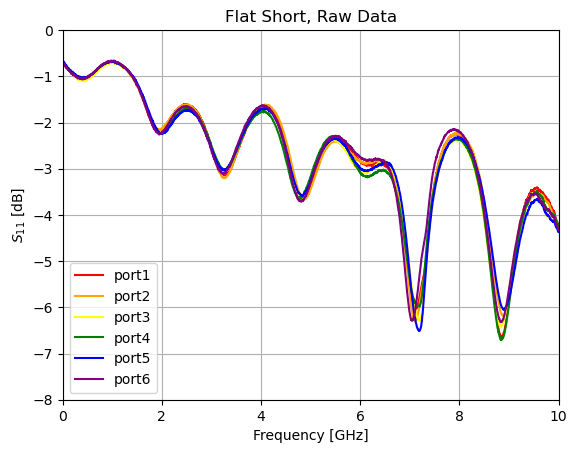

In [25]:
fghz = rf1_rawdata.f/1e9
# plt.plot(fghz,short_reference.s_db[:,0,0],color="black")
plt.plot(fghz,rf1_rawdata.s_db[:,0,0],color="red")
plt.plot(fghz,rf2_rawdata.s_db[:,0,0],color="orange")
plt.plot(fghz,rf3_rawdata.s_db[:,0,0],color="yellow")
plt.plot(fghz,rf4_rawdata.s_db[:,0,0],color="green")
plt.plot(fghz,rf5_rawdata.s_db[:,0,0],color="blue")
plt.plot(fghz,rf6_rawdata.s_db[:,0,0],color="purple")
plt.xlim(0,10)
plt.grid()
plt.ylim(-8,0)
plt.title("Flat Short, Raw Data")
plt.xlabel('Frequency [GHz]')
plt.ylabel('$S_{11}$ [dB]')
plt.legend(("port1", "port2", "port3", "port4", "port5", "port6"))

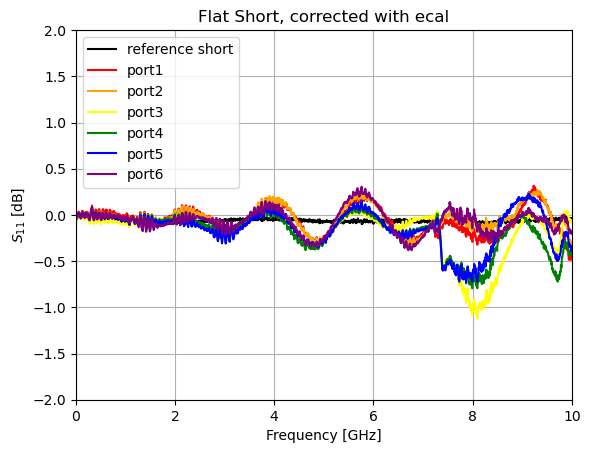

In [27]:
fghz = rf1_scikitrf_corrected.f/1e9
plt.plot(fghz,short_reference.s_db[:,0,0],color="black")
plt.plot(fghz,rf1_scikitrf_corrected.s_db[:,0,0],color="red")
plt.plot(fghz,rf2_scikitrf_corrected.s_db[:,0,0],color="orange")
plt.plot(fghz,rf3_scikitrf_corrected.s_db[:,0,0],color="yellow")
plt.plot(fghz,rf4_scikitrf_corrected.s_db[:,0,0],color="green")
plt.plot(fghz,rf5_scikitrf_corrected.s_db[:,0,0],color="blue")
plt.plot(fghz,rf6_scikitrf_corrected.s_db[:,0,0],color="purple")
plt.xlim(0,10)
plt.grid()
plt.ylim(-2,2)
plt.title("Flat Short, corrected with ecal")
plt.xlabel('Frequency [GHz]')
plt.ylabel('$S_{11}$ [dB]')
plt.legend(("reference short", "port1", "port2", "port3", "port4", "port5", "port6"))

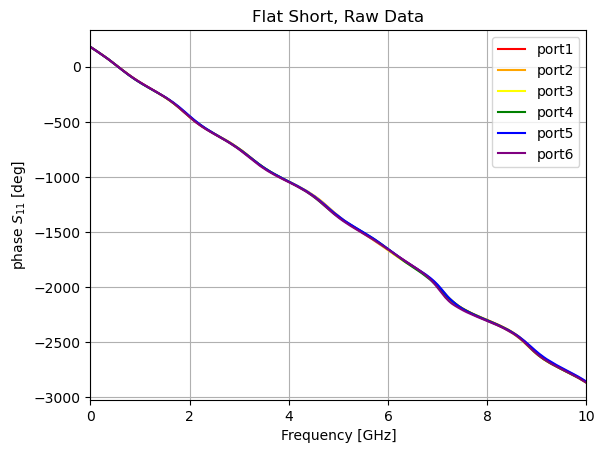

In [29]:
# plt.plot(fghz,short_reference.s_deg_unwrap[:,0,0],color="black")
plt.plot(fghz,rf1_rawdata.s_deg_unwrap[:,0,0],color="red")
plt.plot(fghz,rf2_rawdata.s_deg_unwrap[:,0,0],color="orange")
plt.plot(fghz,rf3_rawdata.s_deg_unwrap[:,0,0],color="yellow")
plt.plot(fghz,rf4_rawdata.s_deg_unwrap[:,0,0],color="green")
plt.plot(fghz,rf5_rawdata.s_deg_unwrap[:,0,0],color="blue")
plt.plot(fghz,rf6_rawdata.s_deg_unwrap[:,0,0],color="purple")
plt.xlim(0,10)
plt.grid()
# plt.ylim(170,190)

plt.title("Flat Short, Raw Data")
plt.xlabel('Frequency [GHz]')
plt.ylabel('phase $S_{11}$ [deg]')
plt.legend(("port1", "port2", "port3", "port4", "port5", "port6"))

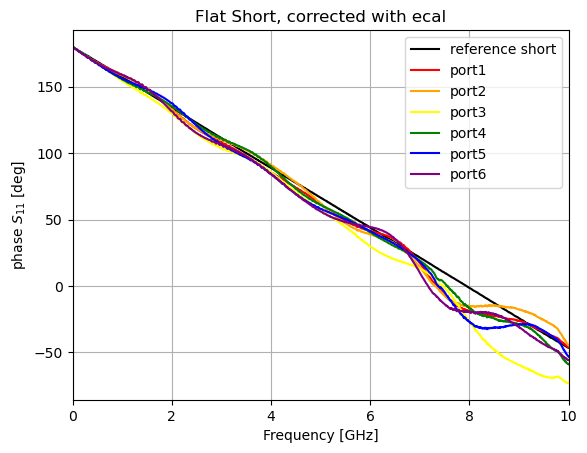

In [31]:
plt.plot(fghz,short_reference.s_deg_unwrap[:,0,0],color="black")
plt.plot(fghz,rf1_scikitrf_corrected.s_deg_unwrap[:,0,0],color="red")
plt.plot(fghz,rf2_scikitrf_corrected.s_deg_unwrap[:,0,0],color="orange")
plt.plot(fghz,rf3_scikitrf_corrected.s_deg_unwrap[:,0,0],color="yellow")
plt.plot(fghz,rf4_scikitrf_corrected.s_deg_unwrap[:,0,0],color="green")
plt.plot(fghz,rf5_scikitrf_corrected.s_deg_unwrap[:,0,0],color="blue")
plt.plot(fghz,rf6_scikitrf_corrected.s_deg_unwrap[:,0,0],color="purple")
plt.xlim(0,10)
plt.grid()
# plt.ylim(170,190)

plt.title("Flat Short, corrected with ecal")
plt.xlabel('Frequency [GHz]')
plt.ylabel('phase $S_{11}$ [deg]')
plt.legend(("reference short", "port1", "port2", "port3", "port4", "port5", "port6"))